# Authenticated records with HMAC

Verify the origin and integrity of a small record shared by two trusted components.

Use a random secret and a fixed byte serialisation. Authenticate the record with HMAC-SHA-256 and verify with compare_digest. A verifier with the secret can also produce tags. Replays require separate handling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hmac, json, secrets

## Run the local experiment

All records used below belong to the small fixture supplied by the example.

{'Original': True, 'Reordered': True, 'Corrected count': False, 'Incomplete tag': False}


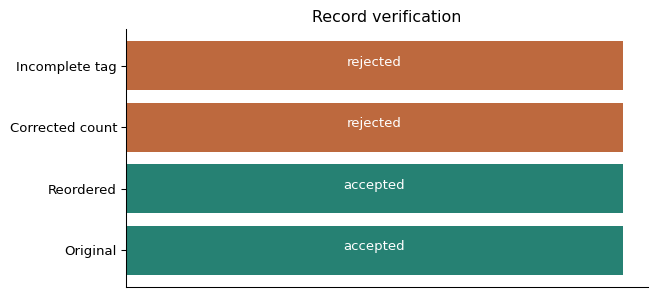

In [2]:
key = secrets.token_bytes(32)


def payload(event):
    return json.dumps(event, sort_keys=True, separators=(",", ":"), allow_nan=False).encode()


event = {"event": "archive-complete", "count": 12}
tag = hmac.digest(key, payload(event), "sha256")
cases = [
    ("Original", event, tag),
    ("Reordered", dict(reversed(list(event.items()))), tag),
    ("Corrected count", {**event, "count": 13}, tag),
    ("Incomplete tag", event, tag[:-1]),
]
out = [
    hmac.compare_digest(hmac.digest(key, payload(e), "sha256"), provided)
    for _, e, provided in cases
]
print(dict(zip([c[0] for c in cases], out)))
assert out == [True, True, False, False]
fig, ax = plt.subplots(figsize=(6.8, 3), constrained_layout=True)
ax.barh([c[0] for c in cases], [1] * 4, color=["#268173" if x else "#bd693e" for x in out])
ax.set(xticks=[], title="Record verification")
[
    ax.text(0.5, i, "accepted" if x else "rejected", ha="center", color="white")
    for i, x in enumerate(out)
]
plt.show()

## Interpreting the result

The reordered mapping verifies because this fixture signs canonical field order. Cross-language deployments need an agreed serialisation specification.

## Exercise

Include a sequence number in the signed bytes and describe the state a receiver must keep to detect reuse.

## References

[RFC 2104, HMAC](https://www.rfc-editor.org/rfc/rfc2104)

[Python, HMAC and constant-time comparison](https://docs.python.org/3/library/hmac.html)